# Phase 8 - Two-Stage Sequencing Detector (GBPUSD)

Pipeline mejorado:
- Etapa 1: detector de cambio (`change/no-change`) sobre secuencia de tokens.
- Etapa 2: clasificador de siguiente token con peso adicional en eventos de cambio.
- Fusión suave: mezcla `stay` + distribución de cambio calibrada en validación walk-forward.

Este notebook ejecuta el script de entrenamiento/evaluación y muestra métricas comparadas contra baseline Markov.

In [1]:
from pathlib import Path
import json
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('.')
PHASE8 = ROOT / 'phases/phase08_two_stage_detector'
RUN_SCRIPT = PHASE8 / 'run_phase8_two_stage_next_token.py'
OUT_DIR = PHASE8 / 'output_phase8_two_stage_GBPUSD'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_phase8_summary.json'
FOLD_CSV = OUT_DIR / 'GBPUSD_phase8_fold_metrics.csv'
PRED_MODEL_CSV = OUT_DIR / 'GBPUSD_phase8_predictions_model.csv'
PRED_BASE_CSV = OUT_DIR / 'GBPUSD_phase8_predictions_baseline.csv'


In [2]:
subprocess.run(['python', str(RUN_SCRIPT)], check=True)
print('Ejecución completada:', RUN_SCRIPT)

Saved summary: ./phases/phase08_two_stage_detector/output_phase8_two_stage_GBPUSD/GBPUSD_phase8_summary.json
Mean metrics: {'baseline_top1_all': 0.8001116010670151, 'baseline_top3_all': 0.8491071914638795, 'baseline_top5_all': 0.8576269802384452, 'baseline_top1_change': 0.0, 'baseline_top3_change': 0.4415898111550285, 'baseline_top5_change': 0.5135046113306984, 'baseline_detector_f1': 0.1920410273022742, 'model_top1_all': 0.8786678643366542, 'model_top3_all': 0.9191436659589526, 'model_top5_all': 0.9532092111709947, 'model_top1_change': 0.0, 'model_top3_change': 0.30654369784804564, 'model_top5_change': 0.5569828722002635, 'model_detector_precision': 0.16724254742547426, 'model_detector_recall': 0.5254721124286342, 'model_detector_f1': 0.25309290096015086, 'model_detector_roc_auc': 0.6221107883566129, 'model_detector_pr_auc': 0.22525457150485037}


Ejecución completada: ./phases/phase08_two_stage_detector/run_phase8_two_stage_next_token.py


In [3]:
summary = json.loads(SUMMARY_JSON.read_text())
fold = pd.read_csv(FOLD_CSV)

print('Model tag:', summary['model_tag'])
print('Source:', summary['source'])
print('n_vocab:', summary['n_vocab'])
print('n_samples_total:', summary['n_samples_total'])
print('change_ratio_total:', round(summary['change_ratio_total'], 4))

pd.DataFrame([summary['mean_metrics']]).T.rename(columns={0: 'mean'}).round(4)

Model tag: phase8_two_stage_change_detector_plus_next_token
Source: phase6_v6_4_hybrid_balanced_tokens
n_vocab: 16
n_samples_total: 1566
change_ratio_total: 0.0907


,mean
baseline_top1_all,0.8001
baseline_top3_all,0.8491
baseline_top5_all,0.8576
baseline_top1_change,0.0000
baseline_top3_change,0.4416
baseline_top5_change,0.5135
baseline_detector_f1,0.1920
model_top1_all,0.8787
model_top3_all,0.9191
model_top5_all,0.9532


In [4]:
metric_pairs = [
    ('baseline_top1_all', 'model_top1_all', 'Top1 all'),
    ('baseline_top3_all', 'model_top3_all', 'Top3 all'),
    ('baseline_top5_all', 'model_top5_all', 'Top5 all'),
    ('baseline_top3_change', 'model_top3_change', 'Top3 change'),
    ('baseline_top5_change', 'model_top5_change', 'Top5 change'),
    ('baseline_detector_f1', 'model_detector_f1', 'Detector F1'),
]

rows = []
for b, m, label in metric_pairs:
    rows.append({
        'metric': label,
        'baseline': float(summary['mean_metrics'].get(b, np.nan)),
        'model': float(summary['mean_metrics'].get(m, np.nan)),
        'delta_model_minus_baseline': float(summary['mean_metrics'].get(m, np.nan) - summary['mean_metrics'].get(b, np.nan)),
    })

cmp_df = pd.DataFrame(rows)
cmp_df.round(4)

,metric,baseline,model,delta_model_minus_baseline
0,Top1 all,0.8001,0.8787,0.0786
1,Top3 all,0.8491,0.9191,0.0700
2,Top5 all,0.8576,0.9532,0.0956
3,Top3 change,0.4416,0.3065,-0.1350
4,Top5 change,0.5135,0.5570,0.0435
5,Detector F1,0.1920,0.2531,0.0611


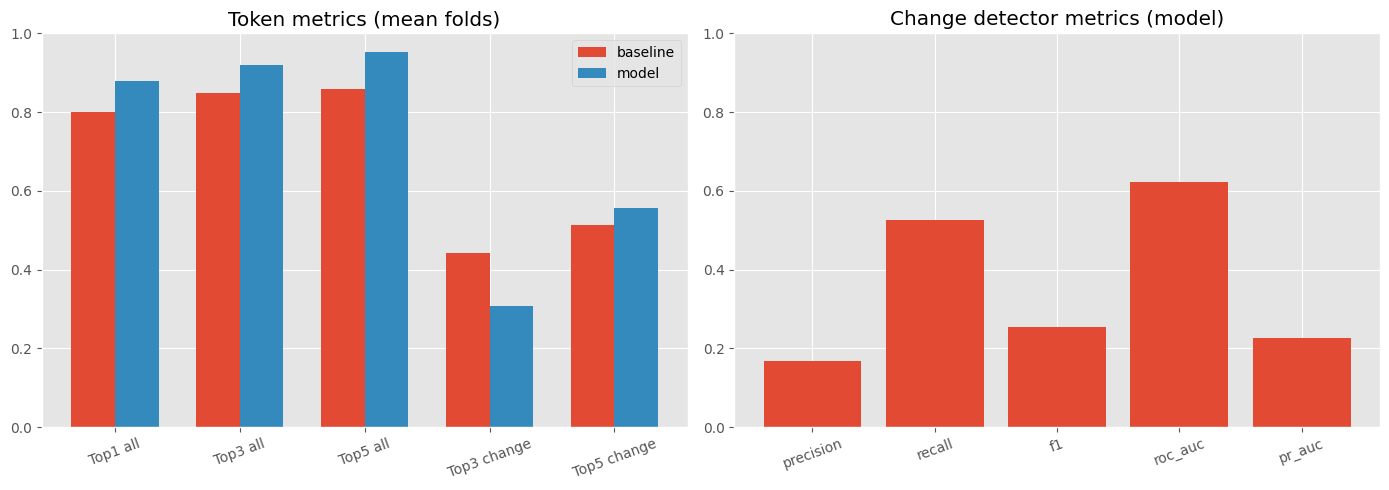

In [5]:
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Token metrics
tok = cmp_df[cmp_df['metric'].isin(['Top1 all', 'Top3 all', 'Top5 all', 'Top3 change', 'Top5 change'])].copy()
x = np.arange(len(tok))
w = 0.35
axes[0].bar(x - w/2, tok['baseline'], width=w, label='baseline')
axes[0].bar(x + w/2, tok['model'], width=w, label='model')
axes[0].set_xticks(x)
axes[0].set_xticklabels(tok['metric'], rotation=20)
axes[0].set_ylim(0, 1)
axes[0].set_title('Token metrics (mean folds)')
axes[0].legend()

# Detector metrics
det_cols = ['model_detector_precision', 'model_detector_recall', 'model_detector_f1', 'model_detector_roc_auc', 'model_detector_pr_auc']
det_vals = [summary['mean_metrics'].get(c, np.nan) for c in det_cols]
axes[1].bar(range(len(det_cols)), det_vals)
axes[1].set_xticks(range(len(det_cols)))
axes[1].set_xticklabels([c.replace('model_detector_', '') for c in det_cols], rotation=20)
axes[1].set_ylim(0, 1)
axes[1].set_title('Change detector metrics (model)')

plt.tight_layout()
plt.show()

In [6]:
fold.round(4)

,fold_id,n_train,n_val,n_test,n_train_change,n_val_change,n_test_change,detector_threshold,final_mix_alpha,baseline_change_threshold,...,model_top3_change,model_top5_change,model_detector_precision,model_detector_recall,model_detector_f1,model_detector_roc_auc,model_detector_pr_auc,baseline_detector_precision,baseline_detector_recall,baseline_detector_f1
0,1,861,156,157,73,10,22,0.4,0.25,0.35,...,0.3182,0.6818,0.2167,0.5909,0.3171,0.6372,0.3027,0.1000,0.2727,0.1463
1,2,1017,157,157,83,22,12,0.5,0.25,0.05,...,0.1667,0.2500,0.0976,0.3333,0.1509,0.6178,0.1092,0.0764,1.0000,0.1420
2,3,1174,157,156,105,12,23,0.5,0.25,0.15,...,0.4348,0.7391,0.1875,0.6522,0.2913,0.6113,0.2638,0.1724,0.8696,0.2878


## Lectura rápida

- Si `Top3/Top5 all` suben, el modelo secuencial aporta ranking contextual general.
- Si `Top3/Top5 change` suben, mejora la predicción de cambios raros.
- `Detector F1/PR-AUC` evalúan qué tan bien la etapa 1 detecta eventos de cambio.
- Usa las métricas por fold para verificar estabilidad temporal (walk-forward).
